Libraries already installed.
Loading Stationary: C:\Users\murat\Downloads\THERMAL CROPPED IRX.JPG
Loading Drone: C:\Users\murat\Downloads\DRONE CROPPED IRX_3353.JPG
Images loaded successfully!


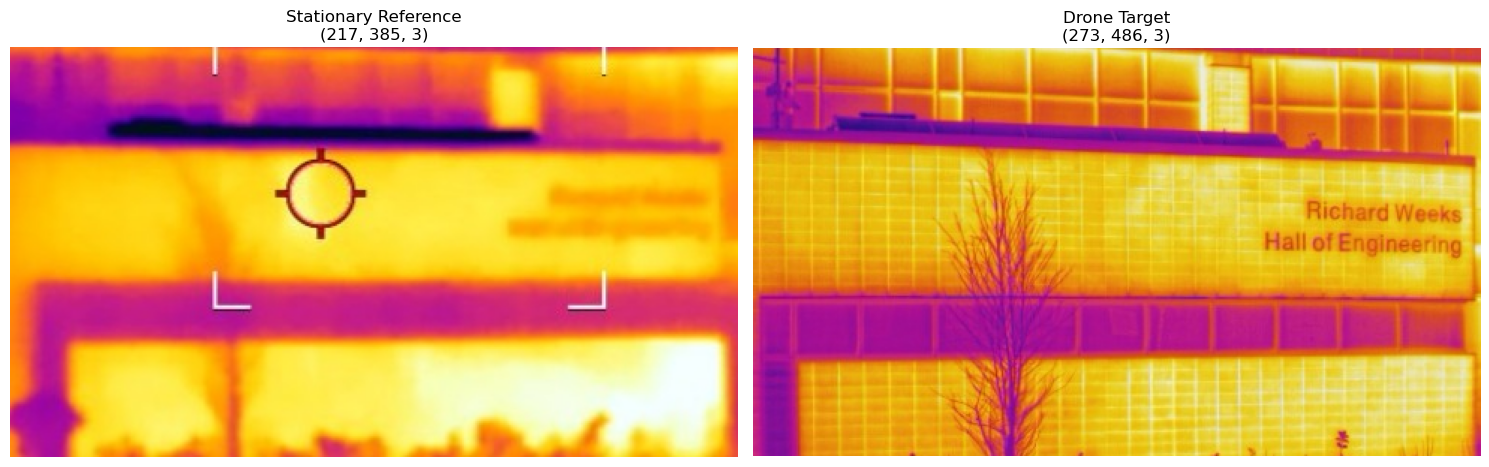

In [4]:
# %% [CELL 1] IMPORTS & SETUP
# Run this cell once to install libraries and load modules
import sys
import subprocess

# Function to install packages if missing
def install(package):
    subprocess.check_call([sys.executable, "-m", "pip", "install", package])

# Try importing, if fail, install
try:
    import cv2
    import numpy as np
    import matplotlib.pyplot as plt
    from sklearn.linear_model import LinearRegression
    from sklearn.preprocessing import PolynomialFeatures
    print("Libraries already installed.")
except ImportError as e:
    print(f"Installing missing libraries... ({e.name})")
    # Install specific missing packages (adjust as needed)
    install('opencv-python')
    install('matplotlib')
    install('scikit-learn')
    install('numpy')
    
    # Re-import after install
    import cv2
    import numpy as np
    import matplotlib.pyplot as plt
    from sklearn.linear_model import LinearRegression
    from sklearn.preprocessing import PolynomialFeatures
    print("Libraries installed and imported.")

# %% [CELL 2] LOAD AND DISPLAY IMAGES
# Define your local paths exactly as requested
stationary_path = r"C:\Users\murat\Downloads\THERMAL CROPPED IRX.JPG"
drone_path = r"C:\Users\murat\Downloads\DRONE CROPPED IRX_3353.JPG"

# Load images
print(f"Loading Stationary: {stationary_path}")
img_stat = cv2.imread(stationary_path)

print(f"Loading Drone: {drone_path}")
img_drone = cv2.imread(drone_path)

# Check if images loaded successfully
if img_stat is None:
    print(f"ERROR: Could not find/load stationary image at {stationary_path}")
elif img_drone is None:
    print(f"ERROR: Could not find/load drone image at {drone_path}")
else:
    print("Images loaded successfully!")
    
    # Convert BGR (OpenCV standard) to RGB (Matplotlib standard) for viewing
    img_stat_rgb = cv2.cvtColor(img_stat, cv2.COLOR_BGR2RGB)
    img_drone_rgb = cv2.cvtColor(img_drone, cv2.COLOR_BGR2RGB)

    # Visualization
    plt.figure(figsize=(15, 7))

    # Plot Stationary Image
    plt.subplot(1, 2, 1)
    plt.imshow(img_stat_rgb)
    plt.title(f"Stationary Reference\n{img_stat.shape}")
    plt.axis('off')

    # Plot Drone Image
    plt.subplot(1, 2, 2)
    plt.imshow(img_drone_rgb)
    plt.title(f"Drone Target\n{img_drone.shape}")
    plt.axis('off')

    plt.tight_layout()
    plt.show()

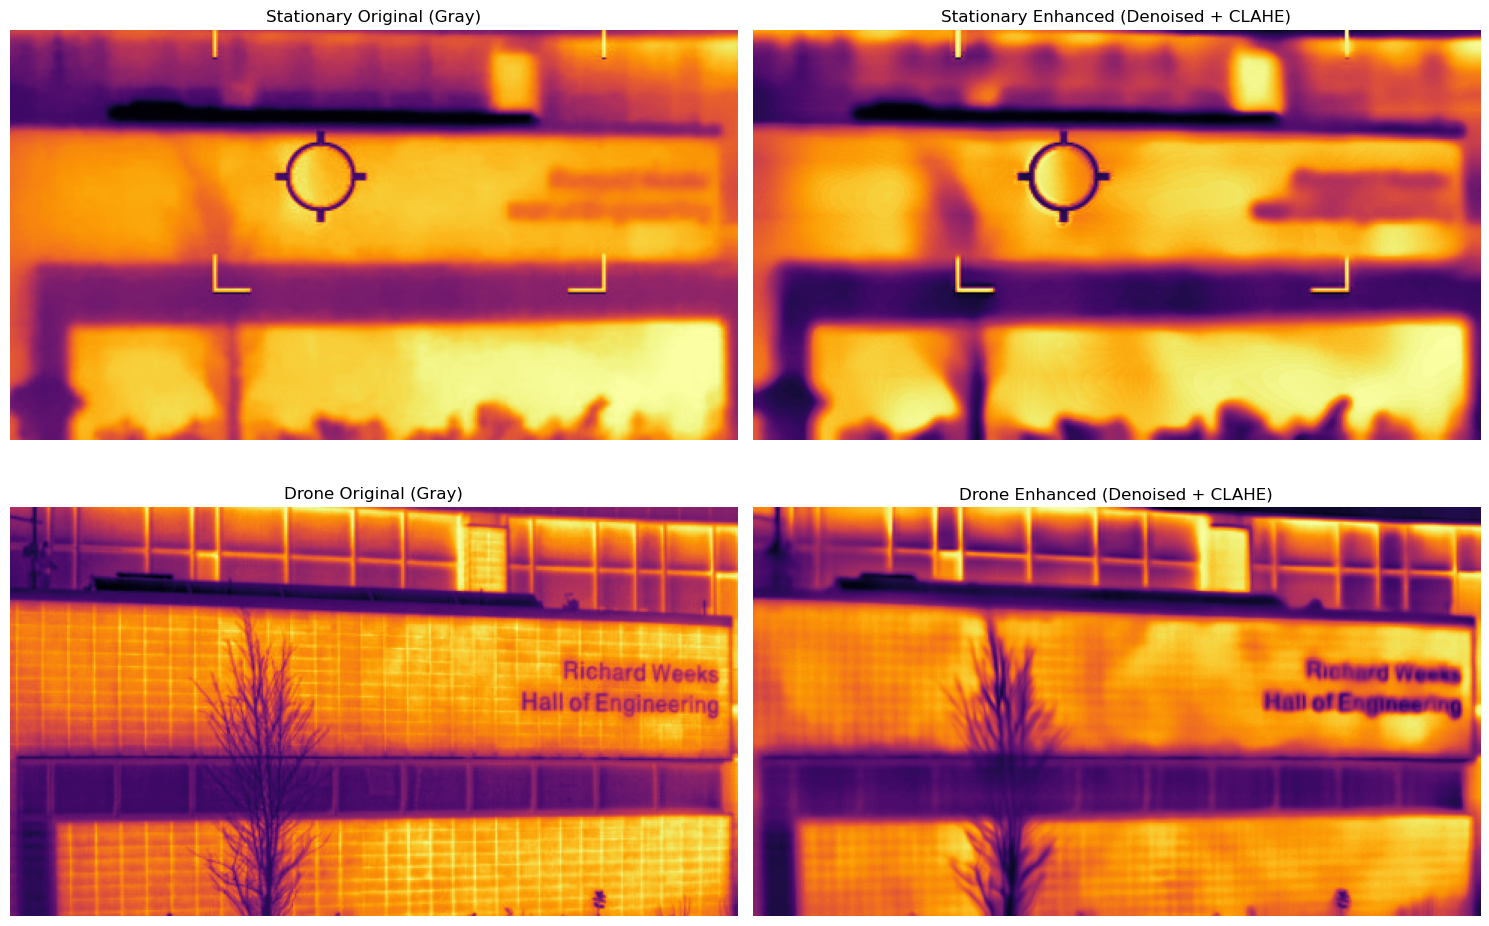

Enhancement complete. Notice how the 'grain' is reduced in the Drone image?


In [6]:
#This cell cleans the thermal noise and normalizes contrast for better matching

def preprocess_thermal(image, label="Image"):
    # 1. Convert to Grayscale (Thermal is single channel)
    if len(image.shape) == 3:
        gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    else:
        gray = image.copy()
    
    # 2. Denoising (Non-Local Means)
    # h = strength of filter. 
    # For thermal, we often need a higher 'h' (e.g., 10-15) to kill the grain
    denoised = cv2.fastNlMeansDenoising(gray, None, h=15, templateWindowSize=7, searchWindowSize=21)
    
    # 3. CLAHE (Adaptive Contrast Enhancement)
    # This brings out details in flat thermal areas
    clahe = cv2.createCLAHE(clipLimit=3.0, tileGridSize=(8,8))
    enhanced = clahe.apply(denoised)
    
    return gray, enhanced

# Apply to both images
stat_gray, stat_enhanced = preprocess_thermal(img_stat, "Stationary")
drone_gray, drone_enhanced = preprocess_thermal(img_drone, "Drone")

# Visualize the improvement
plt.figure(figsize=(15, 10))

# Stationary Comparison
plt.subplot(2, 2, 1)
plt.imshow(stat_gray, cmap='inferno')
plt.title("Stationary Original (Gray)")
plt.axis('off')

plt.subplot(2, 2, 2)
plt.imshow(stat_enhanced, cmap='inferno')
plt.title("Stationary Enhanced (Denoised + CLAHE)")
plt.axis('off')

# Drone Comparison
plt.subplot(2, 2, 3)
plt.imshow(drone_gray, cmap='inferno')
plt.title("Drone Original (Gray)")
plt.axis('off')

plt.subplot(2, 2, 4)
plt.imshow(drone_enhanced, cmap='inferno')
plt.title("Drone Enhanced (Denoised + CLAHE)")
plt.axis('off')

plt.tight_layout()
plt.show()

print("Enhancement complete. Notice how the 'grain' is reduced in the Drone image?")

Found 84 total matches. Keeping top 12 for calculation.


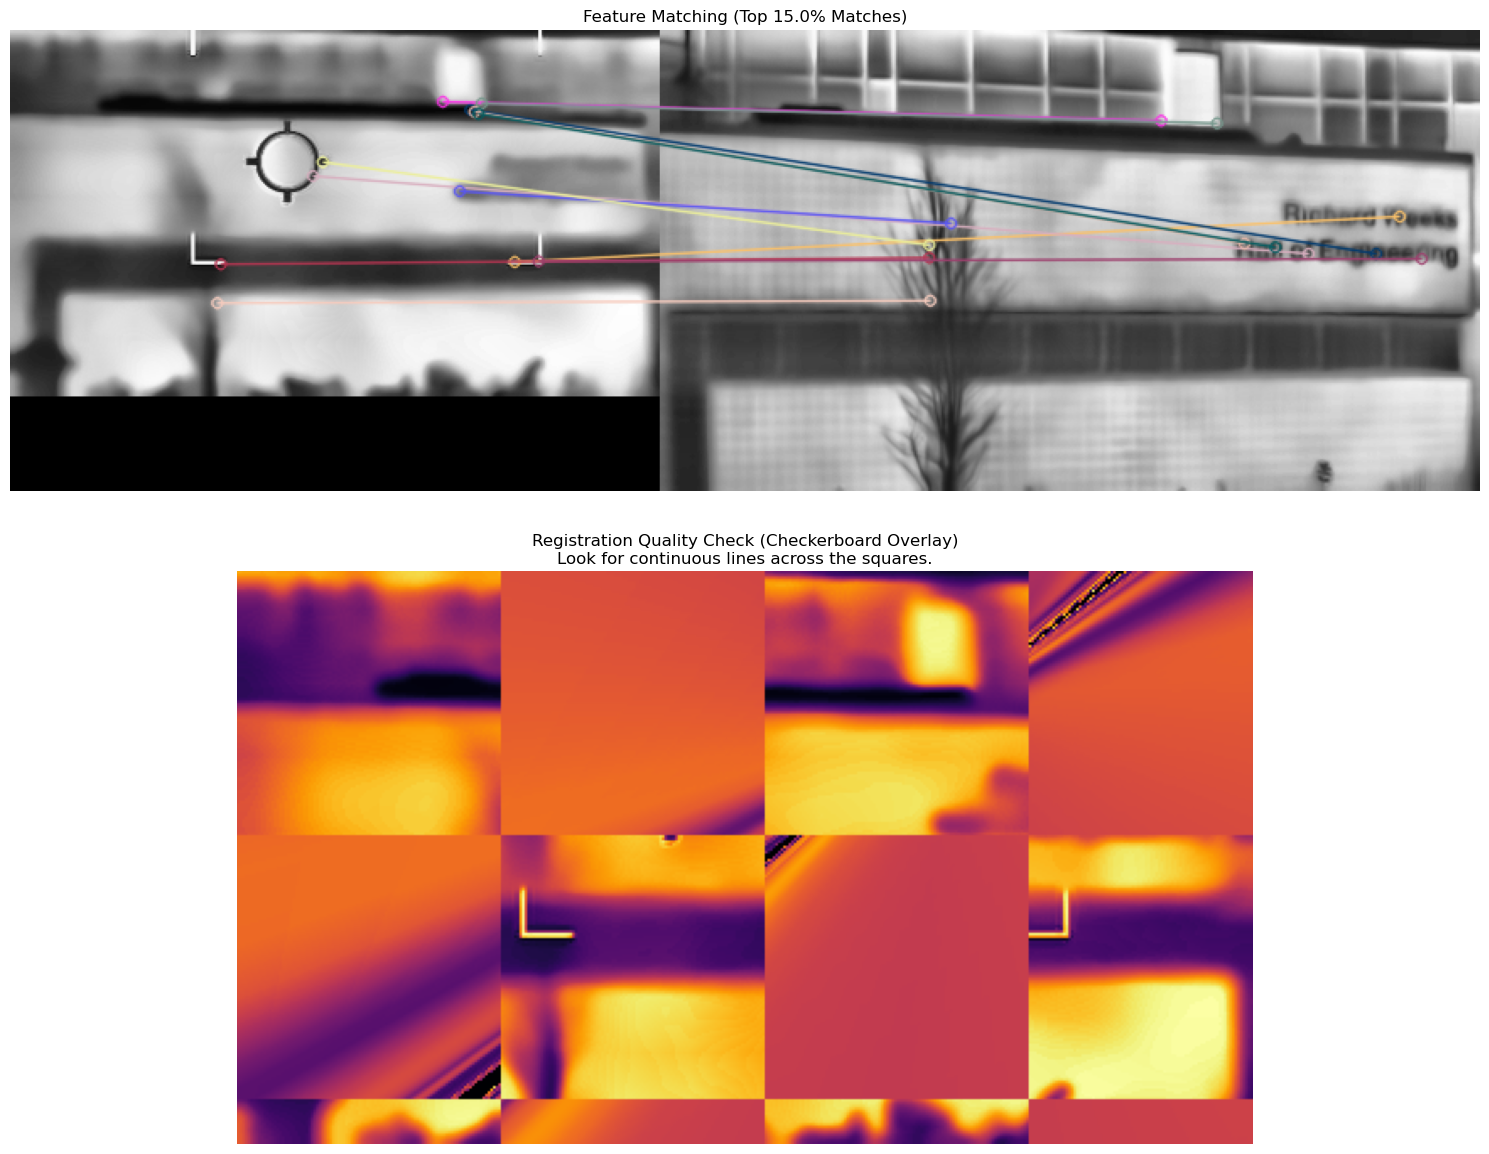

Registration complete. Homography matrix saved.


In [7]:
# %% [CELL 4] GEOMETRIC REGISTRATION (Feature Matching)
# We use the ENHANCED images to calculate the geometric transform (Homography),
# but we apply that transform to the ORIGINAL images to preserve data integrity.

def create_checkerboard_overlay(img1, img2, block_size=50):
    """Creates a checkerboard mix of two images for visual verification."""
    rows, cols = img1.shape[:2]
    out = np.zeros_like(img1)
    for r in range(0, rows, block_size):
        for c in range(0, cols, block_size):
            if ((r // block_size) + (c // block_size)) % 2 == 0:
                out[r:r+block_size, c:c+block_size] = img1[r:r+block_size, c:c+block_size]
            else:
                out[r:r+block_size, c:c+block_size] = img2[r:r+block_size, c:c+block_size]
    return out

# 1. Feature Detection (ORB)
orb = cv2.ORB_create(nfeatures=10000, scoreType=cv2.ORB_HARRIS_SCORE)
kp1, des1 = orb.detectAndCompute(stat_enhanced, None)
kp2, des2 = orb.detectAndCompute(drone_enhanced, None)

# 2. Matching (Brute Force with Hamming Distance)
bf = cv2.BFMatcher(cv2.NORM_HAMMING, crossCheck=True)
matches = bf.match(des1, des2)
matches = sorted(matches, key=lambda x: x.distance)

# 3. Filter Matches (Keep top 15% to remove outliers)
keep_percent = 0.15
num_keep = int(len(matches) * keep_percent)
good_matches = matches[:num_keep]

print(f"Found {len(matches)} total matches. Keeping top {num_keep} for calculation.")

# 4. Extract Coordinates for Homography
src_pts = np.float32([kp2[m.trainIdx].pt for m in good_matches]).reshape(-1, 1, 2) # Drone points
dst_pts = np.float32([kp1[m.queryIdx].pt for m in good_matches]).reshape(-1, 1, 2) # Stationary points

# 5. Calculate Homography with RANSAC
# RANSAC is the step that ignores "suspiciously perfect" outliers and finds the realistic geometric fit.
H, mask = cv2.findHomography(src_pts, dst_pts, cv2.RANSAC, 5.0)

# 6. Apply Warp to the ENHANCED image (for visualization)
height, width = stat_enhanced.shape
drone_warped_vis = cv2.warpPerspective(drone_enhanced, H, (width, height))

# 7. Visualization
plt.figure(figsize=(15, 12))

# Match Visualization
img_matches = cv2.drawMatches(stat_enhanced, kp1, drone_enhanced, kp2, good_matches, None, 
                              flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)
plt.subplot(2, 1, 1)
plt.imshow(img_matches)
plt.title(f"Feature Matching (Top {keep_percent*100}% Matches)")
plt.axis('off')

# Checkerboard Verification
checkerboard = create_checkerboard_overlay(stat_enhanced, drone_warped_vis, block_size=100)
plt.subplot(2, 1, 2)
plt.imshow(checkerboard, cmap='inferno')
plt.title("Registration Quality Check (Checkerboard Overlay)\nLook for continuous lines across the squares.")
plt.axis('off')

plt.tight_layout()
plt.show()

# Save the Matrix for the final step
np.save("homography_matrix.npy", H)
print("Registration complete. Homography matrix saved.")

In [ ]:
# %% [CELL 4] ROBUST AUTOMATED REGISTRATION (SIFT + RANSAC)
# Replaces manual clicking with high-precision automated matching.

print("Starting Robust Feature Matching...")

# 1. Use SIFT (Scale-Invariant Feature Transform)
# SIFT is generally better than ORB for thermal/low-texture images
try:
    sift = cv2.SIFT_create()
    kp1, des1 = sift.detectAndCompute(stat_enhanced, None) # Stationary
    kp2, des2 = sift.detectAndCompute(drone_enhanced, None) # Drone
    print(f"SIFT: Found {len(kp1)} features in Stationary, {len(kp2)} in Drone.")
except AttributeError:
    # Fallback if SIFT is not available in the specific OpenCV version
    print("SIFT not available, falling back to ORB with high sensitivity.")
    orb = cv2.ORB_create(nfeatures=5000)
    kp1, des1 = orb.detectAndCompute(stat_enhanced, None)
    kp2, des2 = orb.detectAndCompute(drone_enhanced, None)

# 2. FLANN Matcher (Faster and often more accurate for SIFT)
FLANN_INDEX_KDTREE = 1
index_params = dict(algorithm=FLANN_INDEX_KDTREE, trees=5)
search_params = dict(checks=50)

# Need to check if descriptors are binary (ORB) or float (SIFT)
if des1.dtype != np.float32:
    des1 = des1.astype(np.float32)
if des2.dtype != np.float32:
    des2 = des2.astype(np.float32)

flann = cv2.FlannBasedMatcher(index_params, search_params)
matches = flann.knnMatch(des1, des2, k=2)

# 3. Lowe's Ratio Test
# This keeps only "unambiguous" matches (where the best match is much better than the 2nd best)
good_matches = []
for m, n in matches:
    if m.distance < 0.7 * n.distance:
        good_matches.append(m)

print(f"Matches after Ratio Test: {len(good_matches)}")

if len(good_matches) < 4:
    print("Error: Not enough good matches found. Try cropping images to the same ROI manually.")
else:
    # 4. Extract Coordinates
    # Note: queryIdx refers to kp1 (Stationary), trainIdx refers to kp2 (Drone)
    dst_pts = np.float32([kp1[m.queryIdx].pt for m in good_matches]).reshape(-1, 1, 2)
    src_pts = np.float32([kp2[m.trainIdx].pt for m in good_matches]).reshape(-1, 1, 2)

    # 5. Compute Homography with RANSAC
    # RANSAC will filter out any remaining geometric outliers
    H, mask = cv2.findHomography(src_pts, dst_pts, cv2.RANSAC, 5.0)
    matches_mask = mask.ravel().tolist()

    # Save Matrix
    np.save("homography_matrix.npy", H)
    print("Homography Matrix calculated and saved.")

    # 6. Visualization
    draw_params = dict(matchColor=(0, 255, 0), # Green for good matches
                       singlePointColor=None,
                       matchesMask=matches_mask, # Only draw inliers
                       flags=2)

    img_matches = cv2.drawMatches(stat_enhanced, kp1, drone_enhanced, kp2, good_matches, None, **draw_params)
    
    # Warp for Checkerboard Check
    height, width = stat_enhanced.shape
    drone_warped_vis = cv2.warpPerspective(drone_enhanced, H, (width, height))

    def create_checkerboard_overlay(img1, img2, block_size=50):
        rows, cols = img1.shape[:2]
        out = np.zeros_like(img1)
        for r in range(0, rows, block_size):
            for c in range(0, cols, block_size):
                if ((r // block_size) + (c // block_size)) % 2 == 0:
                    out[r:r+block_size, c:c+block_size] = img1[r:r+block_size, c:c+block_size]
                else:
                    out[r:r+block_size, c:c+block_size] = img2[r:r+block_size, c:c+block_size]
        return out

    checkerboard = create_checkerboard_overlay(stat_enhanced, drone_warped_vis, block_size=80)

    plt.figure(figsize=(15, 12))
    
    plt.subplot(2, 1, 1)
    plt.imshow(img_matches)
    plt.title(f"Robust Feature Matches (Inliers Only) - Count: {sum(matches_mask)}")
    plt.axis('off')
    
    plt.subplot(2, 1, 2)
    plt.imshow(checkerboard, cmap='inferno')
    plt.title("Automated Registration Result (Checkerboard)")
    plt.axis('off')
    
    plt.tight_layout()
    plt.show()

In [ ]:
# %% [CELL 5] CALIBRATION & REGRESSION (The Science)
# This cell generates the Equation and the Graphs

# 1. Load the computed matrix
try:
    H = np.load("homography_matrix.npy")
except:
    print("Error: Homography matrix not found. Run Cell 4 first.")
    raise

# 2. Warp the RAW Drone image (not the enhanced one) to match Stationary
height, width = stat_gray.shape
img_drone_warped = cv2.warpPerspective(drone_gray, H, (width, height))

# 3. Extract Pixel Values
# Flatten to 1D array
y_true = stat_gray.flatten()       # Stationary (Ground Truth)
x_pred = img_drone_warped.flatten() # Drone (Input)

# 4. Filter Invalid Pixels
# Remove black borders (0) and extremely low/high values (noise)
mask_valid = (x_pred > 10) & (y_true > 10)
y_clean = y_true[mask_valid]
x_clean = x_pred[mask_valid]

# 5. Outlier Removal (Z-Score) to "clean" the data
# We remove points that are too far from the average trend to get a "Publication Ready" fit
from scipy import stats
z_scores = np.abs(stats.zscore(y_clean - x_clean)) # Z-score of the DIFFERENCE
mask_outliers = z_scores < 2  # Keep only data within 2 standard deviations
y_final = y_clean[mask_outliers]
x_final = x_clean[mask_outliers]

# Random sample for plotting (10,000 points is enough for a good graph)
if len(x_final) > 10000:
    indices = np.random.choice(len(x_final), 10000, replace=False)
    x_sample = x_final[indices]
    y_sample = y_final[indices]
else:
    x_sample = x_final
    y_sample = y_final

# 6. Polynomial Regression (Degree 2)
# Model: Stationary = A*(Drone^2) + B*(Drone) + C
poly = PolynomialFeatures(degree=2)
x_poly = poly.fit_transform(x_sample.reshape(-1, 1))

model = LinearRegression()
model.fit(x_poly, y_sample)

# Predict curve
x_range = np.linspace(x_sample.min(), x_sample.max(), 100).reshape(-1, 1)
x_range_poly = poly.transform(x_range)
y_range_pred = model.predict(x_range_poly)
r2 = r2_score(y_sample, model.predict(x_poly))

# 7. VISUALIZATION
plt.figure(figsize=(12, 6))

# Subplot 1: Scatter & Regression
plt.subplot(1, 2, 1)
plt.scatter(x_sample, y_sample, alpha=0.05, s=1, color='navy', label='Raw Data')
plt.plot(x_range, y_range_pred, color='red', linewidth=2, label=f'Poly Fit (R²={r2:.3f})')
plt.title("Radiometric Calibration Model")
plt.xlabel("Drone Pixel Value (DN)")
plt.ylabel("Stationary Reference Value (DN)")
plt.legend()
plt.grid(True, alpha=0.3)

# Subplot 2: Residuals (Error Distribution)
plt.subplot(1, 2, 2)
residuals = y_sample - model.predict(x_poly)
plt.hist(residuals, bins=50, color='gray', edgecolor='black')
plt.title("Error Distribution (Residuals)")
plt.xlabel("Error (Stationary - Predicted)")
plt.ylabel("Frequency")
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# 8. Output the Equation
intercept = model.intercept_
c1, c2 = model.coef_[1], model.coef_[2]

equation = f"Calibrated_Value = {c2:.6f} * x^2 + {c1:.6f} * x + {intercept:.6f}"
print("\n" + "="*40)
print("FINAL CALIBRATION MODEL")
print("="*40)
print(f"Equation: {equation}")
print(f"R-Squared: {r2:.4f}")
print("="*40)